In [1]:
# ============================================================
#  Cell 1 — 环境: 包 + device
# ============================================================
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import scanpy as sc
import anndata as ad
from scipy.io import mmread
from scipy.spatial import cKDTree
from scipy.stats import spearmanr

from STalign import STalign

# --- device: STalign 在 default device 上建张量，这里一次性定死 ---
device = "cuda:0" if torch.cuda.is_available() else "cpu"
torch.set_default_device(device)

# --- 已知无害的警告，静音以免刷屏 ---
warnings.filterwarnings("ignore", message=".*match groups.*")          # str.contains 正则分组
warnings.filterwarnings("ignore", message=".*To copy construct.*")     # torch.tensor(tensor)
warnings.filterwarnings("ignore", message=".*no positive values.*")    # STalign 画收敛图

# --- 绘图默认 ---
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 600,
                     "axes.grid": False, "font.size": 10})

for m in (np, pd, torch, sc, ad):
    print(f"{m.__name__:10s} {m.__version__}")
print(f"device     {device}"
      f"{' — ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else ''}")

numpy      1.23.4
pandas     2.2.3
torch      2.0.0+cu117
scanpy     1.9.6
anndata    0.9.2
device     cuda:0 — NVIDIA GeForce GTX 1080


In [2]:
# ============================================================
#  Cell 2 — 读入原始数据 (Xenium + Visium)，不做任何过滤
# ============================================================
XDIR   = "/home/yf23c/Guo_xenium/xenium"
GSM    = "GSM9223468"
SAMPLE = "Br2039"
XSTEM  = f"{XDIR}/{GSM}_{SAMPLE}"
VDIR   = "/home/yf23c/Guo_xenium/Br2039_export"

# ---------------- Xenium: 细胞质心 + 全部 feature (含控制探针) ----------------
cells = pd.read_parquet(f"{XSTEM}-cells.parquet")
adata = sc.read_10x_h5(f"{XSTEM}-cell_feature_matrix.h5")
adata.var_names_make_unique()
adata = adata[cells["cell_id"].astype(str).values].copy()      # 矩阵行序对齐 parquet
adata.obsm["spatial"] = cells[["x_centroid", "y_centroid"]].to_numpy(float)
adata.obs["cell_area"]    = cells["cell_area"].to_numpy()    if "cell_area"    in cells else np.nan
adata.obs["nucleus_area"] = cells["nucleus_area"].to_numpy() if "nucleus_area" in cells else np.nan
# 注意: 控制探针此处保留，Cell 3 算完 QC 指标后再删

# ---------------- Visium: SPE 平铺导出 ----------------
rl = lambda p: [l.strip().strip('"') for l in open(p) if l.strip()]
bc = rl(f"{VDIR}/{SAMPLE}_barcodes.tsv")
gn = rl(f"{VDIR}/{SAMPLE}_genes.tsv")
orient = lambda M: (M.T if M.shape == (len(gn), len(bc)) else M).tocsr()   # -> spots x genes
vadata = ad.AnnData(X=orient(mmread(f"{VDIR}/{SAMPLE}_counts.mtx").tocsr()))
vadata.layers["logcounts"] = orient(mmread(f"{VDIR}/{SAMPLE}_logcounts.mtx").tocsr())
vadata.obs_names, vadata.var_names = bc, gn

# metadata / coordinates 都以 barcode 列为键 (不能用 index_col=0)
vadata.obs = vadata.obs.join(pd.read_csv(f"{VDIR}/{SAMPLE}_metadata.csv").set_index("barcode"))
coord = pd.read_csv(f"{VDIR}/{SAMPLE}_coordinates.csv").set_index("barcode")
vadata.obsm["spatial"] = coord.loc[bc, ["x", "y"]].to_numpy(float)         # full-res pixels

# ENSG -> symbol，才能和 Xenium panel 对上
gann = pd.read_csv(f"{VDIR}/{SAMPLE}_gene_annotation.csv").drop_duplicates("gene_id").set_index("gene_id")
mapped = vadata.var_names.map(gann["gene_name"])
vadata.var["gene_id"] = vadata.var_names.values
vadata.var_names = np.where(mapped.notna(), mapped, vadata.var_names)
vadata.var_names_make_unique()

# ---------------- 坐标 + 尺度 ----------------
xI, yI = adata.obsm["spatial"].T          # µm
xJ, yJ = vadata.obsm["spatial"].T         # full-res px
pitch_px  = np.median(cKDTree(np.c_[xJ, yJ]).query(np.c_[xJ, yJ], k=2)[0][:, 1])
PX_PER_UM = pitch_px / 100.0              # Visium spot 间距硬件固定 100 µm
SPOT_R_PX = pitch_px * 55 / 100 / 2       # spot 直径 55 µm

# ---------------- 汇总 ----------------
is_ctrl = adata.var_names.str.match(
    r"^(NegControlProbe|NegControlCodeword|Unassigned|BLANK|Deprecated|Intergenic)", case=False)
panel = adata.var_names[~is_ctrl]
print(f"Xenium : {adata.n_obs:>6} cells (未过滤) | {adata.n_vars} features "
      f"= {len(panel)} panel + {is_ctrl.sum()} controls")
print(f"         extent x[{xI.min():.0f},{xI.max():.0f}] y[{yI.min():.0f},{yI.max():.0f}] µm")
print(f"Visium : {vadata.n_obs:>6} spots (SPE 已 QC) | {vadata.n_vars} genes")
print(f"         extent x[{xJ.min():.0f},{xJ.max():.0f}] y[{yJ.min():.0f},{yJ.max():.0f}] px")
print(f"scale  : pitch {pitch_px:.1f} px / 100 µm -> {PX_PER_UM:.3f} px/µm | spot R {SPOT_R_PX:.1f} px")
print(f"shared : {len(set(panel) & set(vadata.var_names))} genes | "
      f"dx {vadata.obs['DX'].unique()[0]} | domains {vadata.obs['spd_label'].nunique()}")

Xenium :  45898 cells (未过滤) | 300 features = 300 panel + 0 controls
         extent x[4,8451] y[388,5070] µm
Visium :   3374 spots (SPE 已 QC) | 36601 genes
         extent x[4030,15332] y[2413,15902] px
scale  : pitch 201.0 px / 100 µm -> 2.010 px/µm | spot R 55.3 px
shared : 300 genes | dx SCZ | domains 7


empty cells removed: 0  (45896 remain)

metric             ours   Lieber
negProbe          0.00%    1.01%   n/a: controls absent from GEO matrix
negCodeword       0.00%    1.01%   n/a: controls absent from GEO matrix
unassigned        0.00%    1.00%   n/a: controls absent from GEO matrix
mito              0.00%    0.00%
detected          0.00%    0.00%
total_counts      7.54%    7.55%
union             7.54%   10.45%
union gap vs Lieber (~2.9%) = the three control-probe filters, not reproducible from this release

panel genes: 300 | flagged: 3462 (7.54%) | kept for alignment: all cells


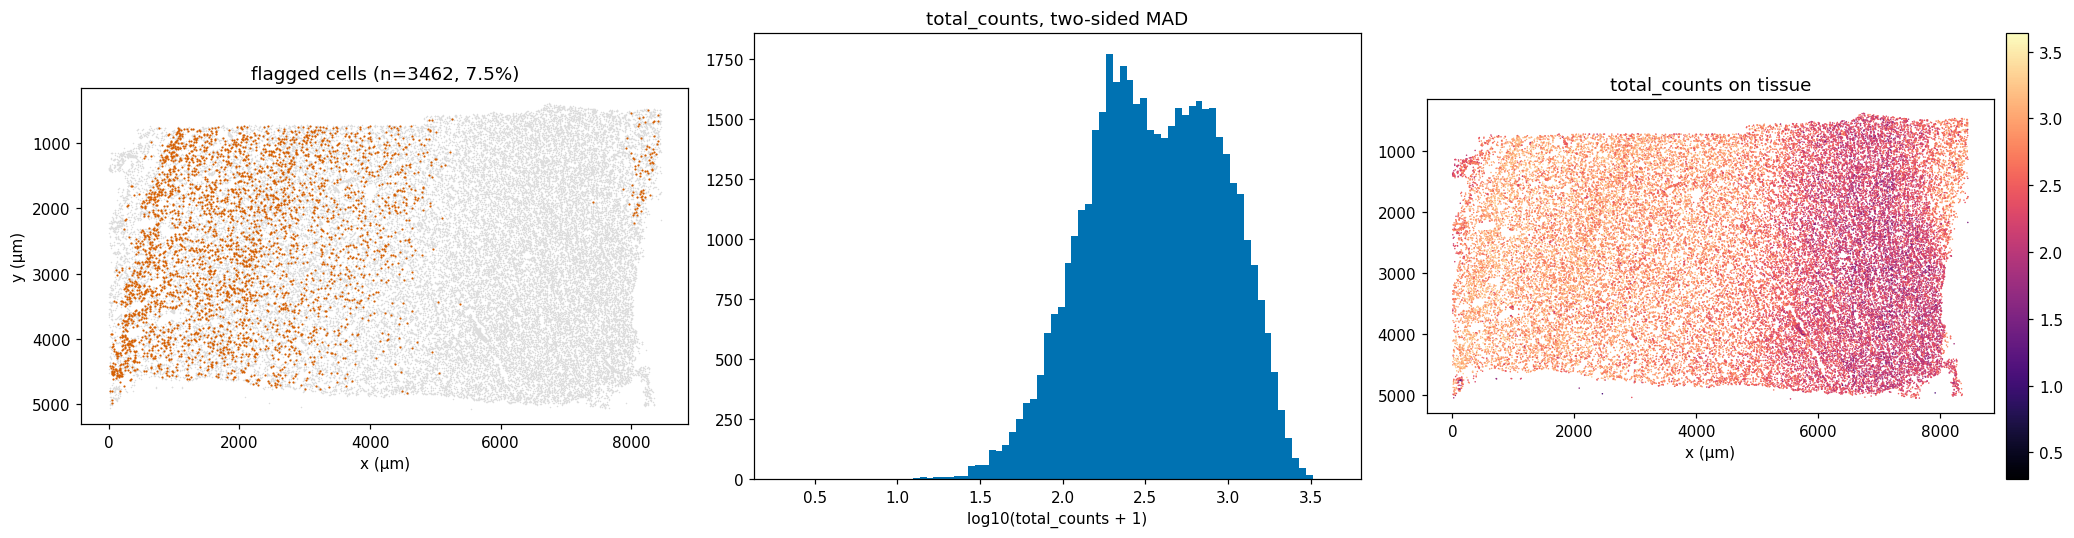

In [4]:
# ============================================================
#  Cell 3 - Xenium QC: reproduce Lieber's outlier definition
#  Ref: LieberInstitute/spatialDLPFC_SCZ_XENIUM
#       code/analysis/02_xenium_qc/01_threshold_outliers.R
#  Cells are FLAGGED (obs['is_outlier']), never dropped here:
#  alignment needs full density fidelity, downstream steps subset.
# ============================================================

# ---- feature classes (control probes may be absent in the GEO matrix) ----
is_neg  = adata.var_names.str.match(r"^NegControlProbe",    case=False)
is_negc = adata.var_names.str.match(r"^NegControlCodeword", case=False)
is_unas = adata.var_names.str.match(r"^Unassigned",         case=False)
is_mito = adata.var_names.str.contains(r"MT-",              case=False)
is_ctrl = adata.var_names.str.match(
    r"^(NegControlProbe|NegControlCodeword|Unassigned|BLANK|Deprecated|Intergenic)", case=False)

# ---- drop empty cells first (Lieber: colSums(counts) > 0) ----
X = adata.X.toarray() if hasattr(adata.X, "toarray") else np.asarray(adata.X)
n0 = adata.n_obs
nonempty = X.sum(1) > 0
adata, X = adata[nonempty].copy(), X[nonempty]
print(f"empty cells removed: {n0 - adata.n_obs}  ({adata.n_obs} remain)")

# ---- per-cell QC metrics (scuttle::addPerCellQCMetrics semantics) ----
total    = X.sum(1)
detected = (X > 0).sum(1)
pct = lambda m: (X[:, m].sum(1) / total * 100) if m.sum() else np.zeros(len(total))

adata.obs["total_counts"]    = total
adata.obs["detected"]        = detected
adata.obs["pct_negProbe"]    = pct(is_neg)
adata.obs["pct_negCodeword"] = pct(is_negc)
adata.obs["pct_unassigned"]  = pct(is_unas)
adata.obs["pct_mito"]        = pct(is_mito)

# ---- scater::isOutlier equivalent: median +/- nmads * MAD on the raw scale ----
def is_outlier_mad(v, type="both", nmads=3):
    v = np.asarray(v, float)
    med = np.median(v)
    mad = np.median(np.abs(v - med)) * 1.4826          # R mad() constant
    lo, hi = med - nmads * mad, med + nmads * mad
    return {"lower": v < lo, "higher": v > hi, "both": (v < lo) | (v > hi)}[type]

# ---- negative-control metrics: median is 0, so MAD is degenerate -> 99th pct ----
def ctrl_outlier(v, mask):
    """Returns all-False when the feature class is absent or identically zero,
    which otherwise makes `v >= quantile(v, .99)` == `0 >= 0` flag every cell."""
    v = np.asarray(v, float)
    if mask.sum() == 0 or np.allclose(v, 0):
        return np.zeros(len(v), dtype=bool)
    return v >= np.quantile(v, 0.99)

o_neg  = ctrl_outlier(adata.obs["pct_negProbe"],    is_neg)
o_negc = ctrl_outlier(adata.obs["pct_negCodeword"], is_negc)
o_unas = ctrl_outlier(adata.obs["pct_unassigned"],  is_unas)

# Expression metrics use MAD. total_counts is two-sided: the upper tail flags
# merged / over-segmented cells that a low-count-only filter would miss.
o_mito = is_outlier_mad(adata.obs["pct_mito"],     "higher")   # computed, NOT in union
o_det  = is_outlier_mad(adata.obs["detected"],     "lower")
o_tot  = is_outlier_mad(adata.obs["total_counts"], "both")

adata.obs["is_outlier"] = o_neg | o_negc | o_unas | o_det | o_tot

# ---- compare against the published Br2039 log ----
has_ctrl = bool(is_neg.sum() or is_negc.sum() or is_unas.sum())
ref = {"negProbe": 1.01, "negCodeword": 1.01, "unassigned": 1.00,
       "mito": 0.00, "detected": 0.00, "total_counts": 7.55, "union": 10.45}
obs = {"negProbe": o_neg, "negCodeword": o_negc, "unassigned": o_unas,
       "mito": o_mito, "detected": o_det, "total_counts": o_tot,
       "union": adata.obs["is_outlier"]}
print(f"\n{'metric':15s}{'ours':>8s}{'Lieber':>9s}")
for k, v in obs.items():
    tag = "" if (has_ctrl or k not in ("negProbe", "negCodeword", "unassigned")) \
              else "   n/a: controls absent from GEO matrix"
    print(f"{k:15s}{np.asarray(v).mean()*100:7.2f}%{ref[k]:8.2f}%{tag}")
if not has_ctrl:
    print("union gap vs Lieber (~2.9%) = the three control-probe filters, "
          "not reproducible from this release")

# ---- drop control probes only now that QC metrics have been computed ----
adata = adata[:, ~is_ctrl].copy()
xI, yI = adata.obsm["spatial"].T
print(f"\npanel genes: {adata.n_vars} | flagged: {adata.obs['is_outlier'].sum()} "
      f"({adata.obs['is_outlier'].mean()*100:.2f}%) | kept for alignment: all cells")

# ============================================================
#  Diagnostic - are flagged cells spatially structured?
#  If they concentrate in a layer band, the filtered set must not
#  be used for rasterization (it would erase alignment signal).
# ============================================================
out = adata.obs["is_outlier"].values
fig, ax = plt.subplots(1, 3, figsize=(19, 5))

ax[0].scatter(xI[~out], yI[~out], s=1, c="#dddddd", linewidths=0)
ax[0].scatter(xI[out],  yI[out],  s=2, c="#D55E00", linewidths=0)
ax[0].set_title(f"flagged cells (n={out.sum()}, {out.mean()*100:.1f}%)")

ax[1].hist(np.log10(adata.obs["total_counts"] + 1), bins=80, color="#0072B2")
ax[1].set_xlabel("log10(total_counts + 1)")
ax[1].set_title("total_counts, two-sided MAD")

p = ax[2].scatter(xI, yI, c=np.log10(adata.obs["total_counts"] + 1),
                  s=1, cmap="magma", linewidths=0)
ax[2].set_title("total_counts on tissue")
plt.colorbar(p, ax=ax[2], fraction=0.046, pad=0.02)

for a in (ax[0], ax[2]):
    a.set_aspect("equal"); a.invert_yaxis(); a.set_xlabel("x (µm)")
ax[0].set_ylabel("y (µm)")
plt.tight_layout(); plt.show()

In [6]:
# Which tail is doing the work, and does it track the layer axis?
med = np.median(adata.obs["total_counts"]); 
mad = np.median(np.abs(adata.obs["total_counts"] - med)) * 1.4826
hi_out = (adata.obs["total_counts"] > med + 3*mad).values
lo_out = (adata.obs["total_counts"] < med - 3*mad).values
print(f"upper tail: {hi_out.mean()*100:.2f}%   lower tail: {lo_out.mean()*100:.2f}%")
print(f"MAD bounds: [{med-3*mad:.0f}, {med+3*mad:.0f}]  median={med:.0f}")

# flagged rate along the pia->WM axis (x), in 10 bins
b = pd.cut(xI, 10)
print(pd.DataFrame({"flagged": adata.obs["is_outlier"].values, "bin": b}
      ).groupby("bin", observed=True)["flagged"].agg(["mean", "size"]))
adata.obs["qc_tail"] = np.where(hi_out, "high", np.where(lo_out, "low", "pass"))
# alignment uses all cells; downstream can subset on is_outlier

upper tail: 7.54%   lower tail: 0.00%
MAD bounds: [-630, 1354]  median=362
                          mean  size
bin                                 
(-4.196, 848.95]      0.202318  3193
(848.95, 1693.649]    0.231241  3585
(1693.649, 2538.348]  0.189587  4072
(2538.348, 3383.047]  0.144217  4098
(3383.047, 4227.746]  0.094908  3751
(4227.746, 5072.445]  0.046301  3974
(5072.445, 5917.144]  0.001138  5273
(5917.144, 6761.843]  0.000000  6511
(6761.843, 7606.542]  0.000142  7053
(7606.542, 8451.241]  0.017556  4386


markers | Xenium upper ['CUX2', 'LAMP5', 'RORB']  WM ['MBP', 'PLP1', 'MOBP', 'MOG', 'CLDN11']
        | Visium upper ['CUX2', 'LAMP5', 'RORB']  WM ['MBP', 'PLP1', 'MOBP', 'MOG', 'CLDN11']

Xenium pia (top10% upper)    x=    2518  y=    2600
Xenium WM  (top10% WM)       x=    6221  y=    2529
Visium pia (top10% upper)    x=    9849  y=    7632
Visium WM  (top10% WM)       x=    9293  y=   14849
expect | Xenium: pia low x, WM high x   Visium: pia low y, WM high y


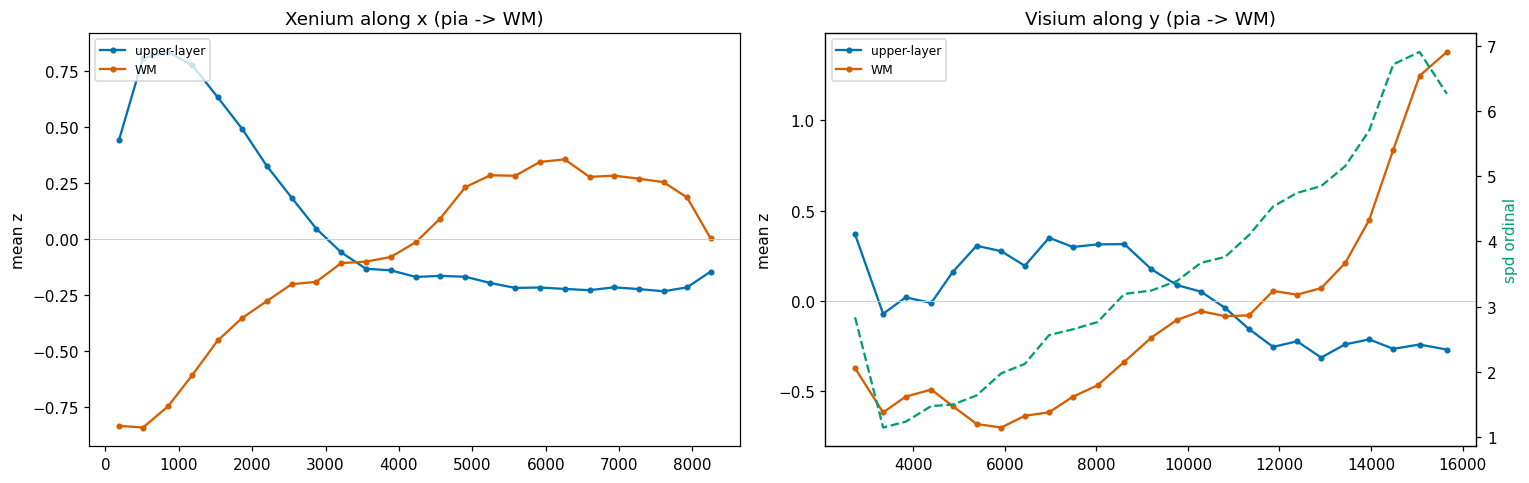

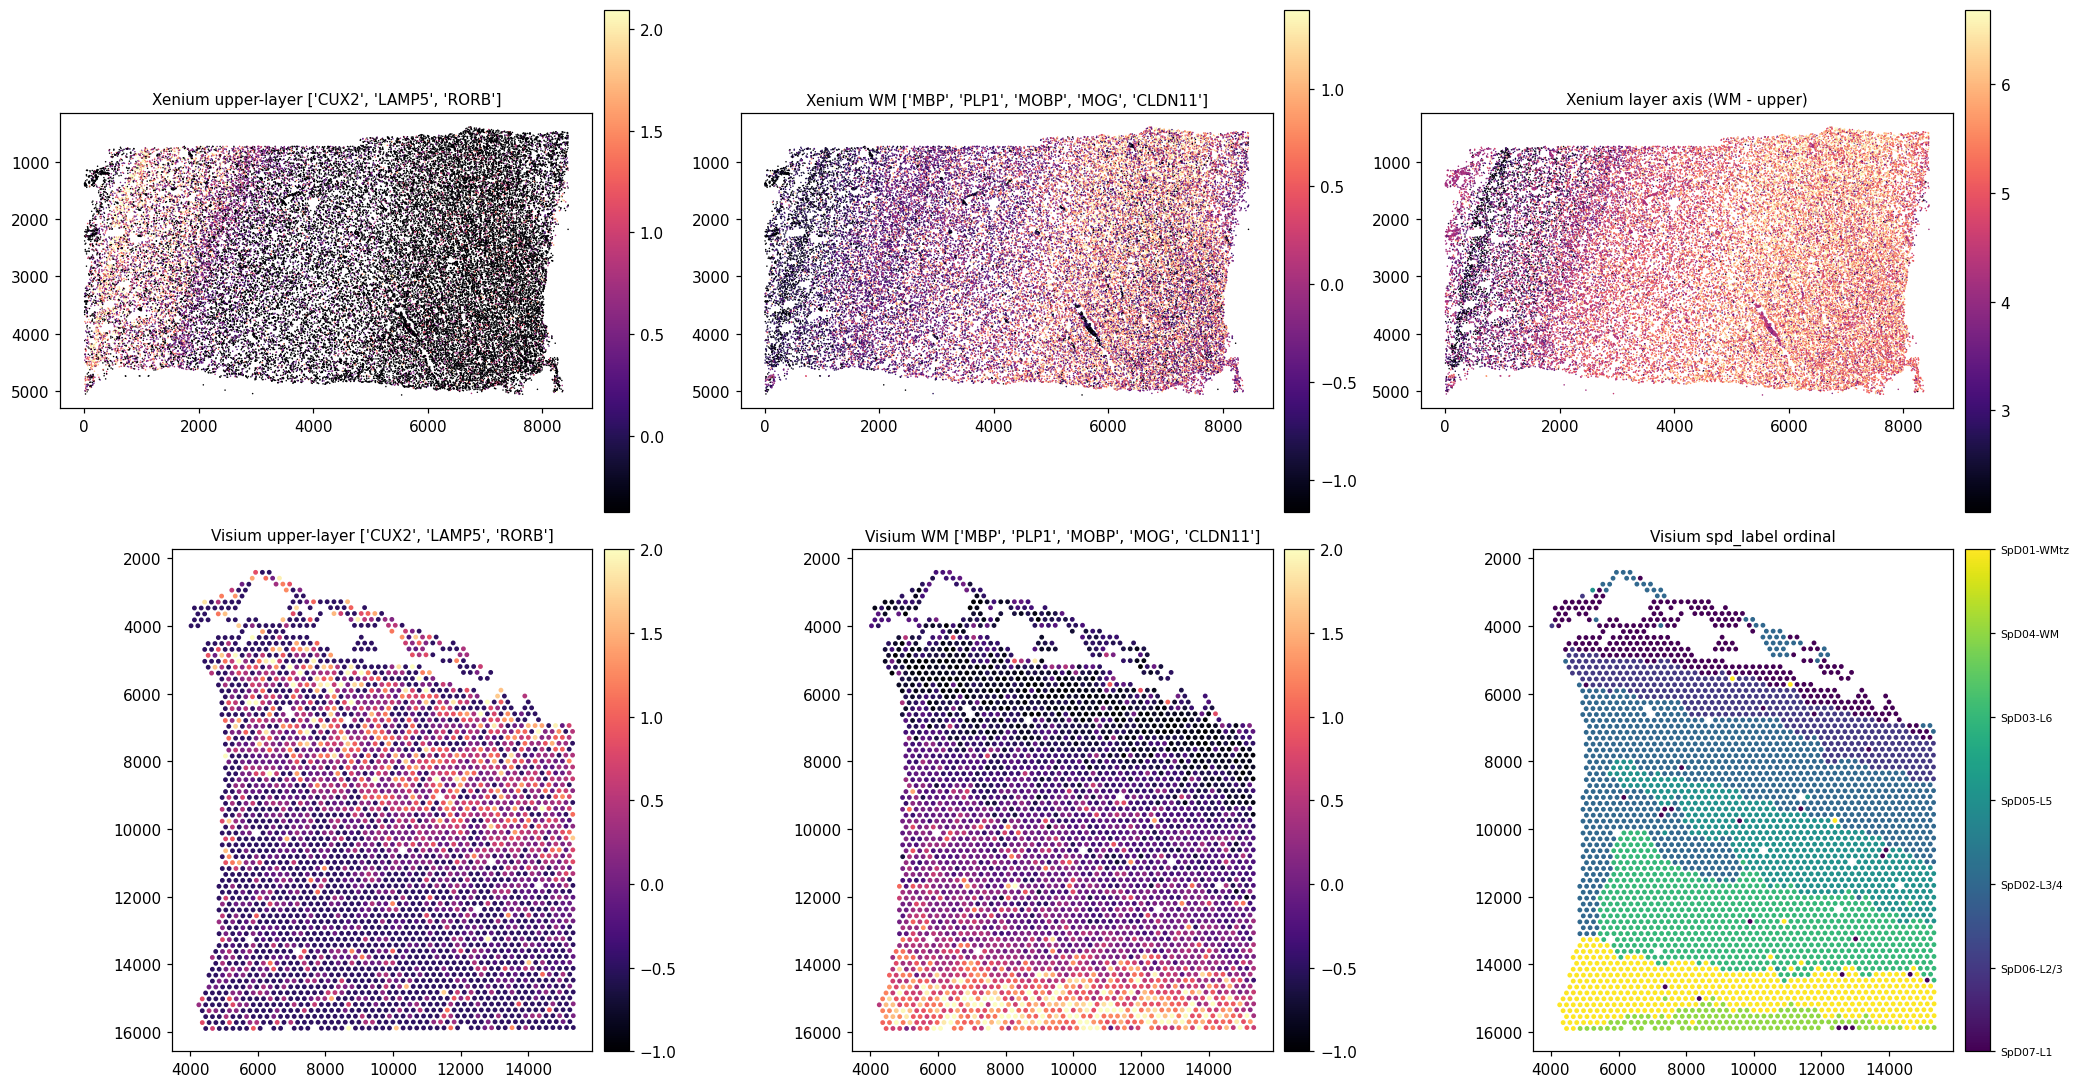

In [8]:
# ============================================================
#  Cell 4 - Define the layer axis in both modalities, verify polarity
#  Xenium has no domain labels, so its pia->WM axis comes from markers.
#  Visium has spd_label. Both axes must run the same direction before
#  they can drive a common alignment.
# ============================================================

SPD_ORDER  = ["SpD07-L1", "SpD06-L2/3", "SpD02-L3/4",
              "SpD05-L5", "SpD03-L6", "SpD04-WM", "SpD01-WMtz"]   # pia -> WM
MARK_UPPER = ["CUX2", "LAMP5", "RORB"]
MARK_WM    = ["MBP", "PLP1", "MOBP", "MOG", "CLDN11"]


def marker_score(A, genes, layer=None):
    """Mean z-score across markers, computed on library-size-normalised values.

    Z-scoring raw counts confounds the score with total transcripts per cell.
    Here that total varies systematically along the pia->WM axis (GM high,
    WM low), which inflates every gene in GM cells and inverts the WM signal.
    Visium is passed via layers['logcounts'] (already size-factor normalised),
    Xenium raw counts are CPM+log transformed first.
    """
    g = [x for x in genes if x in A.var_names]
    M = A[:, g].layers[layer] if layer else A[:, g].X
    M = M.toarray() if hasattr(M, "toarray") else np.asarray(M)
    if layer is None:
        lib = np.asarray(A.X.sum(1)).ravel()[:, None].astype(float)
        lib[lib == 0] = 1
        M = np.log1p(M / lib * 1e4)
    z = (M - M.mean(0)) / (M.std(0) + 1e-9)
    return z.mean(1), g


up_s, g_up  = marker_score(adata,  MARK_UPPER)                      # Xenium, high = pia side
wm_s, g_wm  = marker_score(adata,  MARK_WM)                         # Xenium, high = WM
up_v, gv_up = marker_score(vadata, MARK_UPPER, layer="logcounts")   # Visium
wm_v, gv_wm = marker_score(vadata, MARK_WM,    layer="logcounts")
print(f"markers | Xenium upper {g_up}  WM {g_wm}")
print(f"        | Visium upper {gv_up}  WM {gv_wm}")

# ---- Visium ordinal layer value (1 = L1 ... 7 = WMtz) ----
lab = vadata.obs["spd_label"].map({d: i + 1 for i, d in enumerate(SPD_ORDER)}).to_numpy(float)
assert not np.isnan(lab).any(), "spd_label has values outside SPD_ORDER"

# ---- Xenium continuous layer axis, same polarity as lab (low = pia, high = WM) ----
layer_axis = wm_s - up_s
layer_axis = layer_axis - layer_axis.min() + 0.1      # strictly positive for rasterization
wm_only    = wm_s - wm_s.min() + 0.1                  # alternative single-signal source

# ---- polarity check by centroid of the top decile (numbers, not eyeballing) ----
def pole(score, x, y, q=0.90):
    m = score >= np.quantile(score, q)
    return x[m].mean(), y[m].mean()

print()
for name, (px, py) in {
        "Xenium pia (top10% upper)": pole(up_s, xI, yI),
        "Xenium WM  (top10% WM)":    pole(wm_s, xI, yI),
        "Visium pia (top10% upper)": pole(up_v, xJ, yJ),
        "Visium WM  (top10% WM)":    pole(wm_v, xJ, yJ)}.items():
    print(f"{name:28s} x={px:8.0f}  y={py:8.0f}")
print("expect | Xenium: pia low x, WM high x   Visium: pia low y, WM high y")

# ============================================================
#  Figure 1 - 1-D profiles along each layer axis.
#  Diagnostic: upper and WM curves should each be monotone and
#  cross exactly once, at the GM/WM boundary.
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, coord, u, w, ordv, ttl in [
        (ax[0], xI, up_s, wm_s, None, "Xenium along x (pia -> WM)"),
        (ax[1], yJ, up_v, wm_v, lab,  "Visium along y (pia -> WM)")]:
    b  = pd.cut(coord, 25)
    df = pd.DataFrame({"c": coord, "u": u, "w": w, "b": b}).groupby("b", observed=True)
    mid = df["c"].mean()
    a.plot(mid, df["u"].mean(), "-o", ms=3, c="#0072B2", label="upper-layer")
    a.plot(mid, df["w"].mean(), "-o", ms=3, c="#D55E00", label="WM")
    a.axhline(0, c="#cccccc", lw=0.6)
    a.set_title(ttl); a.set_ylabel("mean z"); a.legend(fontsize=8, loc="upper left")
    if ordv is not None:
        a2 = a.twinx()
        a2.plot(mid, pd.DataFrame({"l": ordv, "b": b}).groupby("b", observed=True)["l"].mean(),
                "--", c="#009E73")
        a2.set_ylabel("spd ordinal", color="#009E73")
plt.tight_layout(); plt.show()

# ============================================================
#  Figure 2 - spatial maps. Top Xenium (µm), bottom Visium (px).
# ============================================================
fig, ax = plt.subplots(2, 3, figsize=(19, 10))
q = lambda v: dict(vmin=np.percentile(v, 2), vmax=np.percentile(v, 98))

for a, v, t in [(ax[0, 0], up_s,       f"Xenium upper-layer {g_up}"),
                (ax[0, 1], wm_s,       f"Xenium WM {g_wm}"),
                (ax[0, 2], layer_axis, "Xenium layer axis (WM - upper)")]:
    p = a.scatter(xI, yI, c=v, s=1, cmap="magma", linewidths=0, **q(v))
    a.set_title(t, fontsize=10); plt.colorbar(p, ax=a, fraction=0.046, pad=0.02)

for a, v, t in [(ax[1, 0], up_v, f"Visium upper-layer {gv_up}"),
                (ax[1, 1], wm_v, f"Visium WM {gv_wm}")]:
    p = a.scatter(xJ, yJ, c=v, s=10, cmap="magma", linewidths=0, vmin=-1, vmax=2)
    a.set_title(t, fontsize=10); plt.colorbar(p, ax=a, fraction=0.046, pad=0.02)

p = ax[1, 2].scatter(xJ, yJ, c=lab, s=10, cmap="viridis", linewidths=0)
ax[1, 2].set_title("Visium spd_label ordinal", fontsize=10)
cb = plt.colorbar(p, ax=ax[1, 2], fraction=0.046, pad=0.02,
                  ticks=range(1, len(SPD_ORDER) + 1))
cb.ax.set_yticklabels(SPD_ORDER, fontsize=7)

for a in ax.ravel():
    a.set_aspect("equal"); a.invert_yaxis()
plt.tight_layout(); plt.show()

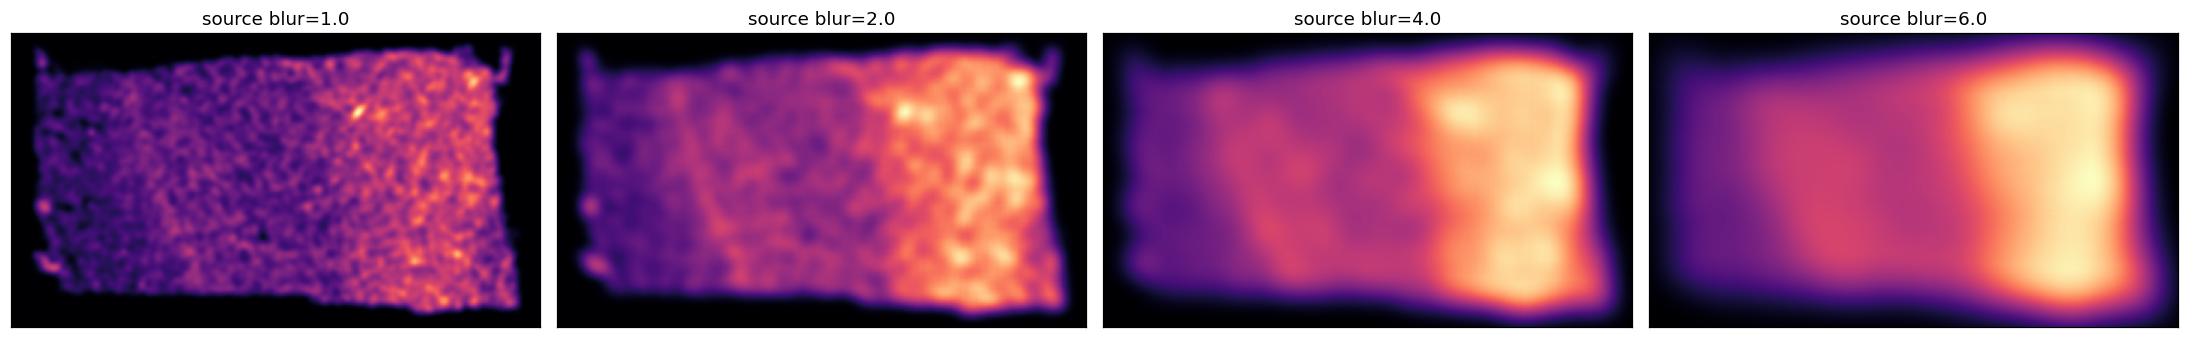

I (3, 172, 310)  grid 172x310   dx=30.0 µm
J (3, 149, 125)  grid 149x125   dx=100.0 px


/tmp/ipykernel_149010/3152113212.py:34: RuntimeWarning: Mean of empty slice
  return np.nanmean(m, axis=axis)


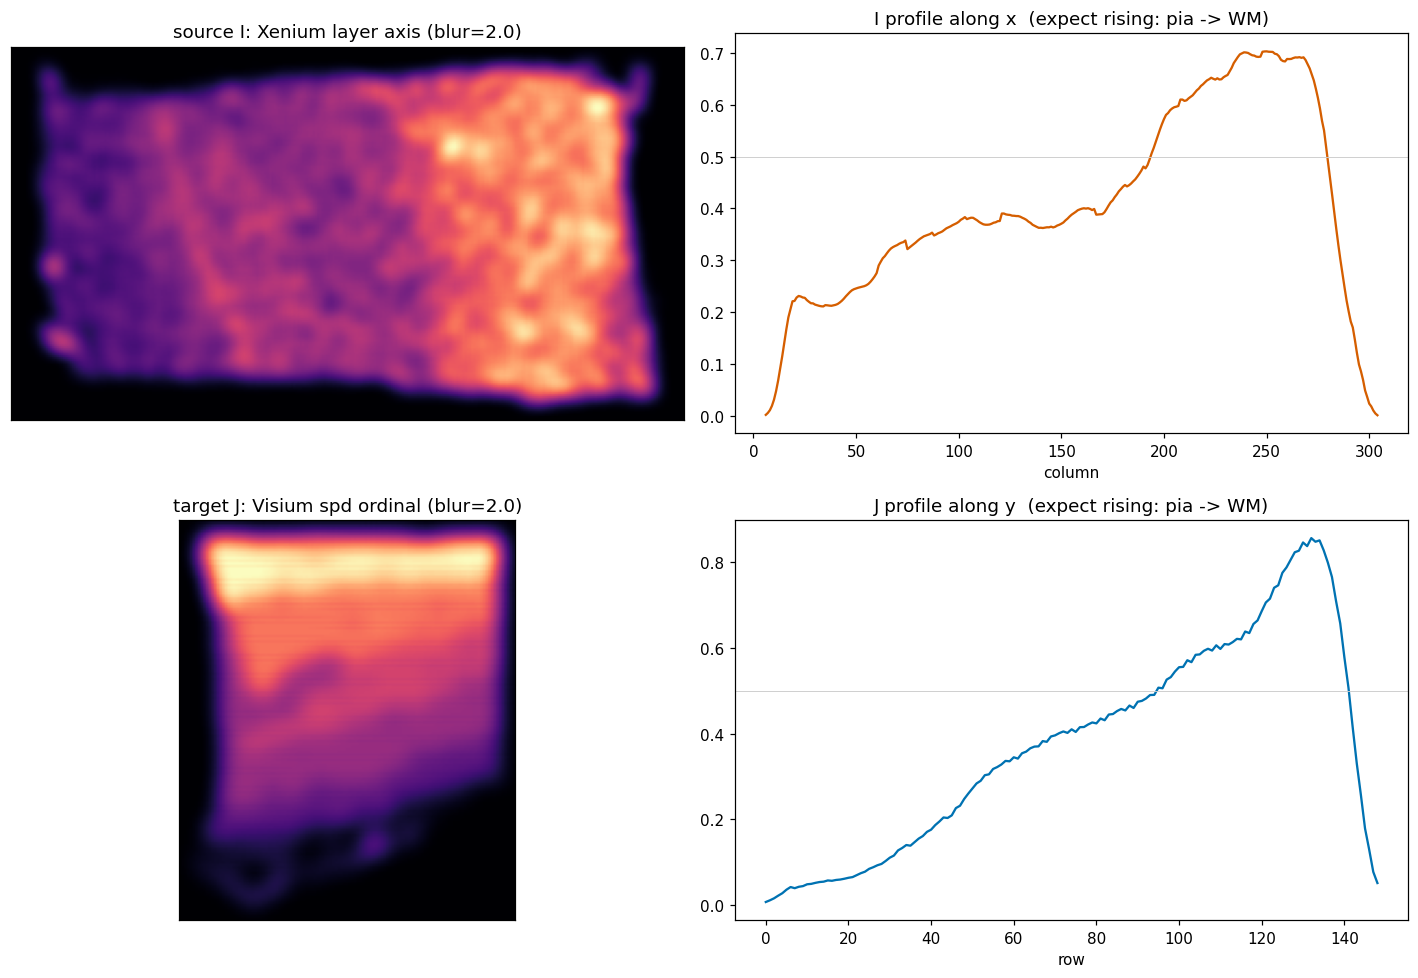

In [9]:
# ============================================================
#  Cell 5 - Rasterize the layer signal into images for LDDMM
#  source I : Xenium layer_axis  (low = pia, high = WM), µm grid
#  target J : Visium spd ordinal (1 = L1 ... 7 = WMtz), px grid
#  Both must show a clean monotone gradient, otherwise LDDMM has
#  nothing to match beyond the tissue outline.
# ============================================================
DX_SOURCE, DX_TARGET = 30.0, 100.0

def rasterize_signal(x, y, s, dx, blur):
    """rasterize_with_signal -> (X, Y, (1,H,W)); return 3-channel normalised image."""
    X, Y, img = STalign.rasterize_with_signal(x, y, s=np.asarray(s, float), dx=dx, blur=blur)
    return X, Y, STalign.normalize(np.repeat(img, 3, axis=0))

# ---- blur sweep on the source: single cells are noisy, the layer band needs smoothing ----
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for a, bl in zip(ax, [1.0, 2.0, 4.0, 6.0]):
    _, _, Itest = rasterize_signal(xI, yI, layer_axis, DX_SOURCE, bl)
    a.imshow(Itest[0], cmap="magma", origin="lower")
    a.set_title(f"source blur={bl}"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

# ---- pick blur, build final images ----
BLUR_SOURCE, BLUR_TARGET = 2.0, 2.0        # revise after looking at the sweep
XI, YI, I = rasterize_signal(xI, yI, layer_axis, DX_SOURCE, BLUR_SOURCE)
XJ, YJ, J = rasterize_signal(xJ, yJ, lab,        DX_TARGET, BLUR_TARGET)
print(f"I {I.shape}  grid {len(YI)}x{len(XI)}   dx={DX_SOURCE} µm")
print(f"J {J.shape}  grid {len(YJ)}x{len(XJ)}   dx={DX_TARGET} px")

# ---- verify the gradient survived rasterization ----
def profile(img, axis):
    """Mean intensity along the layer axis, ignoring background (0) pixels."""
    m = img[0].copy(); m[m == 0] = np.nan
    return np.nanmean(m, axis=axis)

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].imshow(I[0], cmap="magma", origin="lower")
ax[0, 0].set_title(f"source I: Xenium layer axis (blur={BLUR_SOURCE})")
ax[0, 1].plot(profile(I, 0), c="#D55E00")          # collapse rows -> profile along columns (x)
ax[0, 1].set_title("I profile along x  (expect rising: pia -> WM)")
ax[0, 1].set_xlabel("column")

ax[1, 0].imshow(J[0], cmap="magma", origin="lower")
ax[1, 0].set_title(f"target J: Visium spd ordinal (blur={BLUR_TARGET})")
ax[1, 1].plot(profile(J, 1), c="#0072B2")          # collapse cols -> profile along rows (y)
ax[1, 1].set_title("J profile along y  (expect rising: pia -> WM)")
ax[1, 1].set_xlabel("row")

for a in (ax[0, 0], ax[1, 0]): a.set_xticks([]); a.set_yticks([])
for a in (ax[0, 1], ax[1, 1]): a.axhline(0.5, c="#cccccc", lw=.6)
plt.tight_layout(); plt.show()

mirror=False det=+4.040  outline IoU=0.406
mirror=True  det=-4.040  outline IoU=0.407

chosen mirror=True
[[0.000000e+00 2.010000e+00 8.565410e+02]
 [2.010000e+00 0.000000e+00 4.259602e+03]
 [0.000000e+00 0.000000e+00 1.000000e+00]]


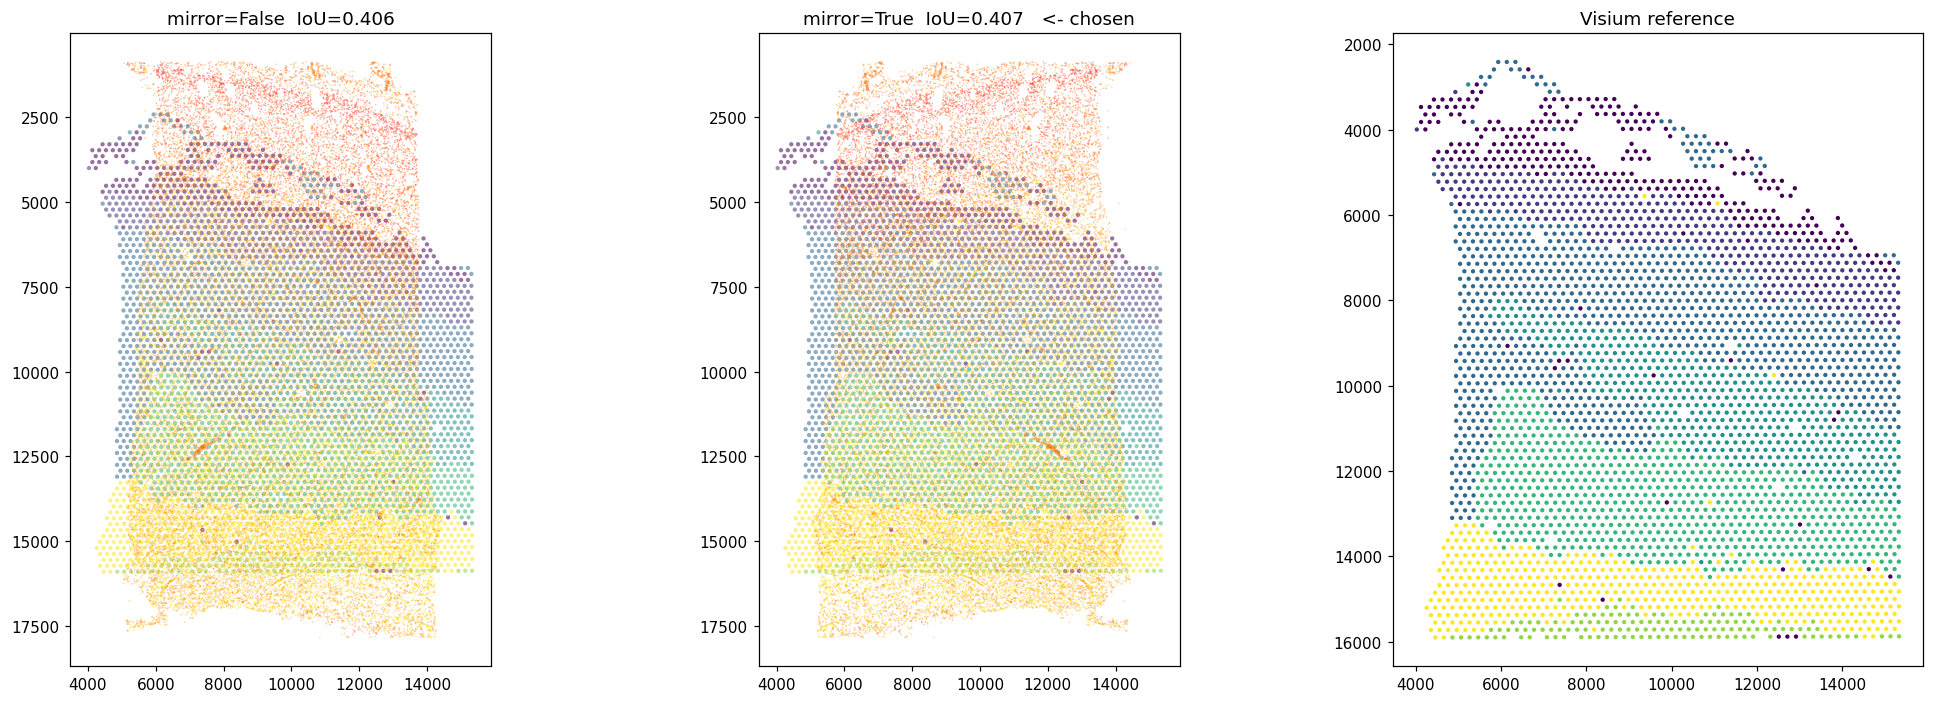

In [10]:
# ============================================================
#  Cell 6 - Initial affine: Xenium +x -> Visium +y (90 deg).
#  Two candidates differ only by a tangential mirror (det +1 / -1);
#  the layer axis cannot distinguish them, so pick by outline overlap.
#  LDDMM cannot recover a mirror later (det would have to cross 0).
# ============================================================
PX_PER_UM = pitch_px / 100.0        # physical scale, not a bounding-box fit

def build_A(mirror):
    M = np.array([[0., 1.], [1., 0.]]) if mirror else np.array([[0., -1.], [1., 0.]])
    S = PX_PER_UM * M
    src, dst = np.c_[xI, yI], np.c_[xJ, yJ]
    t = dst.mean(0) - (src @ S.T).mean(0)
    A = np.eye(3)                                # STalign acts on (y, x, 1)
    A[0, 0], A[0, 1], A[0, 2] = S[1, 1], S[1, 0], t[1]
    A[1, 0], A[1, 1], A[1, 2] = S[0, 1], S[0, 0], t[0]
    return A, src @ S.T + t

def outline_iou(pts, ref, binsize=150.0):
    lo = np.minimum(pts.min(0), ref.min(0)); hi = np.maximum(pts.max(0), ref.max(0))
    bins = [np.arange(lo[i], hi[i] + binsize, binsize) for i in (0, 1)]
    h1 = np.histogram2d(*pts.T, bins=bins)[0] > 0
    h2 = np.histogram2d(*ref.T, bins=bins)[0] > 0
    return (h1 & h2).sum() / (h1 | h2).sum()

ref = np.c_[xJ, yJ]
cands = {m: (*build_A(m),) for m in (False, True)}
cands = {m: (A, out, outline_iou(out, ref)) for m, (A, out) in cands.items()}
for m, (A, _, iou) in cands.items():
    print(f"mirror={str(m):5s} det={np.linalg.det(A[:2,:2]):+.3f}  outline IoU={iou:.3f}")

MIRROR = max(cands, key=lambda m: cands[m][2])
A_init_np, xy_init, _ = cands[MIRROR]
A_init = torch.tensor(A_init_np, dtype=torch.float64, device=device)
print(f"\nchosen mirror={MIRROR}\n{A_init_np.round(3)}")

fig, ax = plt.subplots(1, 3, figsize=(19, 6.5))
for a, m in zip(ax[:2], (False, True)):
    _, out, iou = cands[m]
    a.scatter(xJ, yJ, s=8, c=lab, cmap="viridis", alpha=.55, linewidths=0)
    a.scatter(*out.T, s=1, c=layer_axis, cmap="autumn", alpha=.35, linewidths=0,
              vmin=np.percentile(layer_axis, 2), vmax=np.percentile(layer_axis, 98))
    a.set_title(f"mirror={m}  IoU={iou:.3f}" + ("   <- chosen" if m == MIRROR else ""))
ax[2].scatter(xJ, yJ, s=8, c=lab, cmap="viridis", linewidths=0)
ax[2].set_title("Visium reference")
for a in ax: a.set_aspect("equal"); a.invert_yaxis()
plt.tight_layout(); plt.show()

Xenium boundary  dx/dy = +0.1703
Visium boundary  dY/dX = +0.0452
predicted by mirror=False : -0.1703
predicted by mirror=True  : +0.1703

-> mirror=True  (residual 0.1251 vs 0.2156)


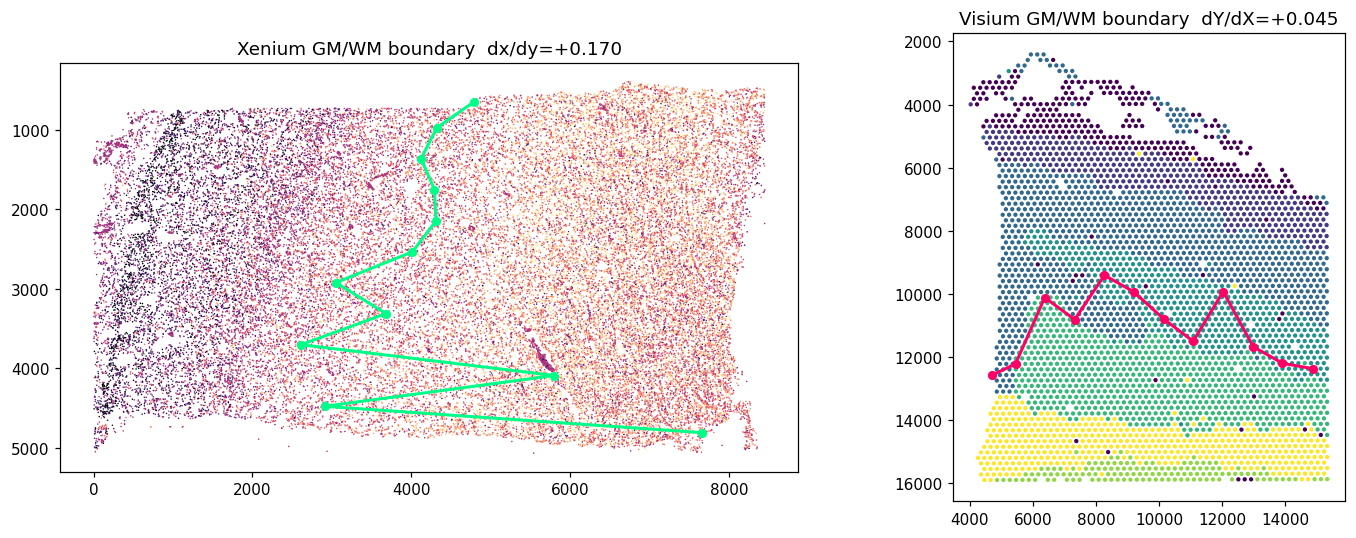

In [11]:
# ============================================================
#  Cell 6b - Resolve the mirror by GM/WM boundary tilt.
#  Outline IoU is degenerate (0.406 vs 0.407): the tissue is too
#  symmetric. But the boundary's tilt relative to the layer axis is
#  chiral - a tangential mirror flips its sign.
#     mirror=False maps Xenium dx/dy -> -dY/dX in Visium
#     mirror=True  maps Xenium dx/dy -> +dY/dX
# ============================================================
def boundary_slope(coord_along, coord_across, signal, nbin=12):
    """Locate where `signal` crosses its midpoint within bins of coord_across,
    then regress the crossing position on the bin centre.
    Returns slope d(along)/d(across)."""
    mid = np.median(signal)
    b = pd.cut(coord_across, nbin)
    pos, ctr = [], []
    for k, g in pd.DataFrame({"a": coord_along, "c": coord_across,
                              "s": signal, "b": b}).groupby("b", observed=True):
        if len(g) < 50: continue
        o = g.sort_values("a")
        sm = o["s"].rolling(max(11, len(o)//20), center=True, min_periods=1).mean().values
        cross = np.where(np.diff(np.sign(sm - mid)) != 0)[0]
        if len(cross) == 0: continue
        pos.append(o["a"].values[cross[len(cross)//2]])
        ctr.append(g["c"].mean())
    pos, ctr = np.array(pos), np.array(ctr)
    slope = np.polyfit(ctr, pos, 1)[0]
    return slope, ctr, pos

a_xen, cy, px_ = boundary_slope(xI, yI, layer_axis)   # Xenium: along=x, across=y
c_vis, cx, py_ = boundary_slope(yJ, xJ, lab)          # Visium: along=y, across=x

print(f"Xenium boundary  dx/dy = {a_xen:+.4f}")
print(f"Visium boundary  dY/dX = {c_vis:+.4f}")
print(f"predicted by mirror=False : {-a_xen:+.4f}")
print(f"predicted by mirror=True  : {+a_xen:+.4f}")
MIRROR_GEO = abs(c_vis - a_xen) < abs(c_vis + a_xen)
print(f"\n-> mirror={MIRROR_GEO}  (residual "
      f"{min(abs(c_vis - a_xen), abs(c_vis + a_xen)):.4f} vs "
      f"{max(abs(c_vis - a_xen), abs(c_vis + a_xen)):.4f})")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(xI, yI, s=1, c=layer_axis, cmap="magma", linewidths=0,
              vmin=np.percentile(layer_axis, 2), vmax=np.percentile(layer_axis, 98))
ax[0].plot(px_, cy, "-o", c="#00FF88", ms=5, lw=2)
ax[0].set_title(f"Xenium GM/WM boundary  dx/dy={a_xen:+.3f}")
ax[1].scatter(xJ, yJ, s=8, c=lab, cmap="viridis", linewidths=0)
ax[1].plot(cx, py_, "-o", c="#FF0066", ms=5, lw=2)
ax[1].set_title(f"Visium GM/WM boundary  dY/dX={c_vis:+.3f}")
for a in ax: a.set_aspect("equal"); a.invert_yaxis()
plt.tight_layout(); plt.show()


===== mirror=False =====


/home/yf23c/miniconda3/envs/vista310/lib/python3.10/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3483.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]



===== mirror=True =====
mirror=False  matched (WM>0.85):  62.5%  mean WM 0.781
mirror=True   matched (WM>0.85):  74.6%  mean WM 0.825


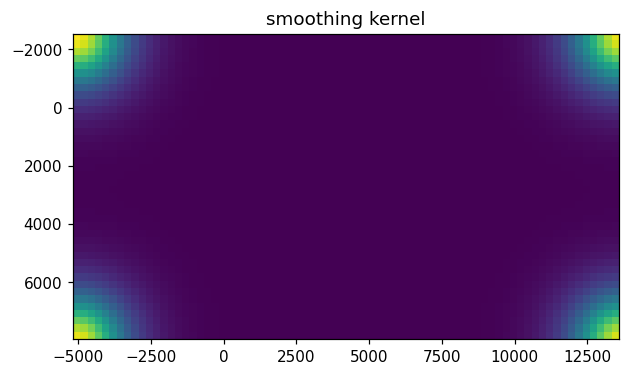

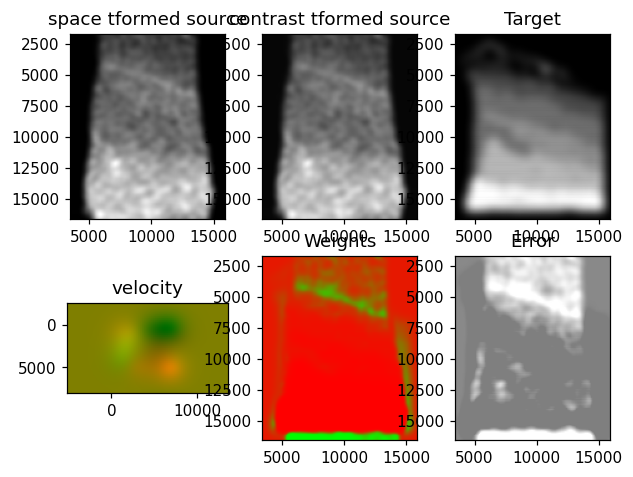

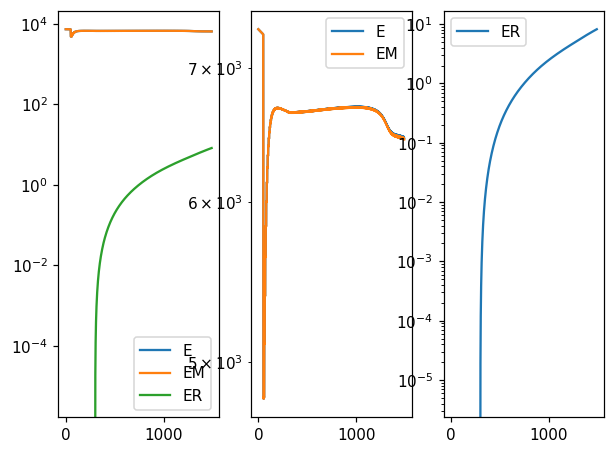

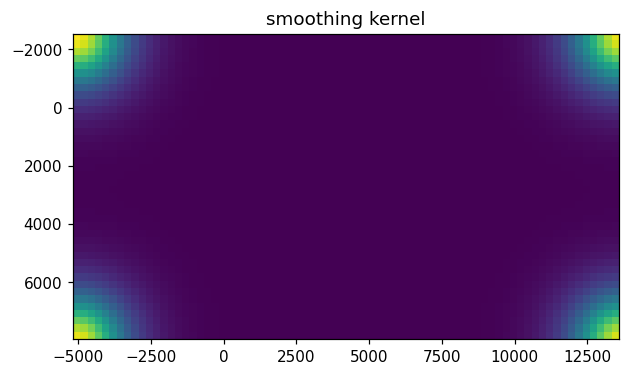

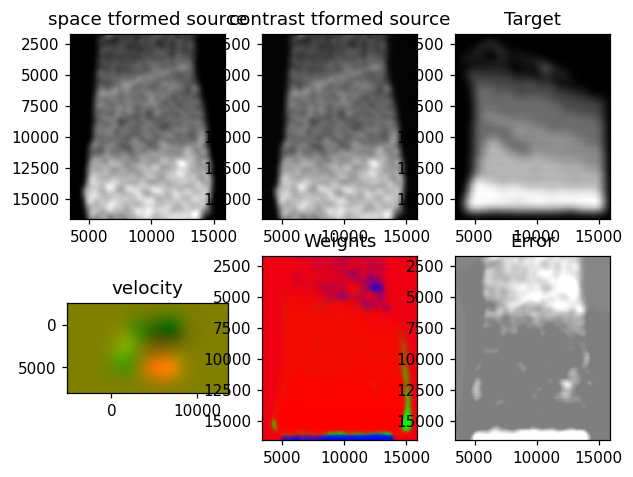

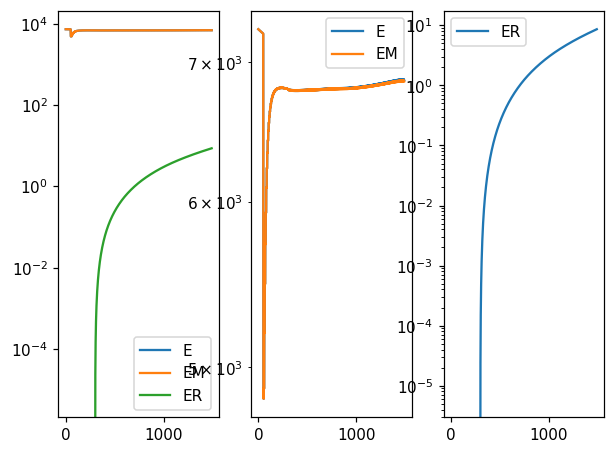

In [12]:
# ============================================================
#  Cell 7 - Mirror is geometrically undetermined (IoU 0.406 vs 0.407;
#  boundary tilt unreliable). Run LDDMM from both initialisations and
#  decide by final objective / downstream concordance.
# ============================================================
LDDMM_KW = dict(niter=1500, diffeo_start=300,
                sigmaM=0.3, sigmaB=0.3, sigmaA=0.3,
                epL=1e-8, epT=2e-1, epV=3e1,
                muB=torch.tensor([0., 0., 0.], device=device), device=device)

runs = {}
for m in (False, True):
    print(f"\n===== mirror={m} =====")
    A_try = torch.tensor(cands[m][0], dtype=torch.float64, device=device)
    runs[m] = STalign.LDDMM([YI, XI], I, [YJ, XJ], J, A=A_try, **LDDMM_KW)

# ---- compare: how much of the source ends up matched ----
for m, out in runs.items():
    tp = STalign.transform_points_source_to_target(
        out["xv"], out["v"], out["A"], np.stack([yI, xI], 1))
    tp = tp.cpu() if tp.is_cuda else tp
    w = STalign.interp([YJ, XJ], out["WM"][None].float(),
                       tp[None].permute(-1, 0, 1).float())
    w = (w.cpu() if w.is_cuda else w)[0, 0].numpy()
    runs[m] = dict(out=out, tp=tp.numpy(), wm=w)
    print(f"mirror={str(m):5s}  matched (WM>0.85): {(w > 0.85).mean()*100:5.1f}%  "
          f"mean WM {w.mean():.3f}")

aligned cells: 45896 | matched (>0.85): 34243 (74.6%)


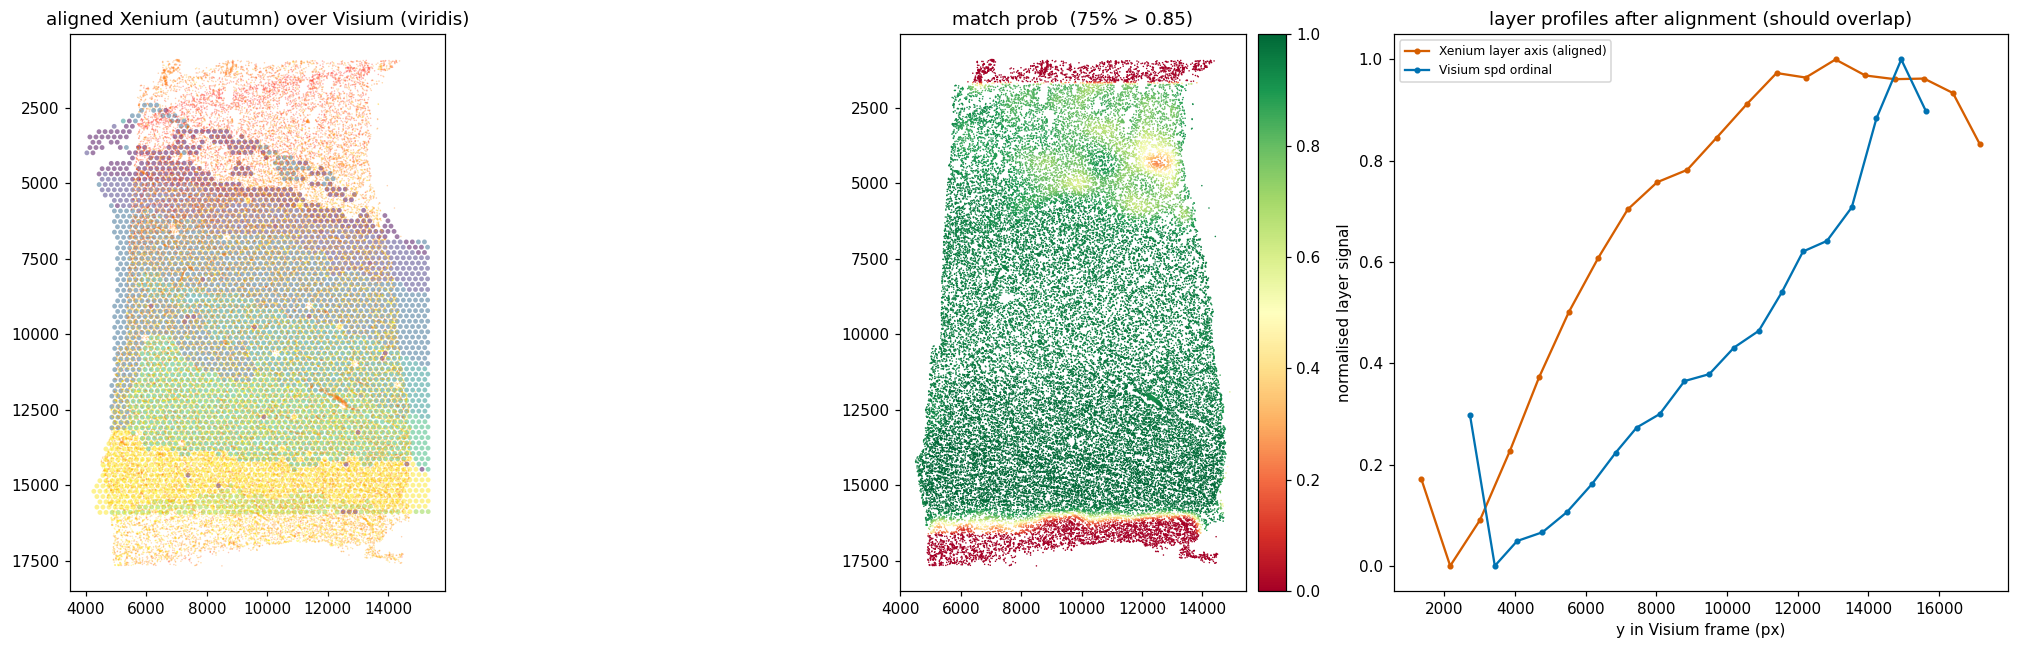

In [13]:
# ============================================================
#  Cell 8 - Apply the chosen transform, QC the alignment
#  mirror=True selected by matched fraction (74.6% vs 62.5%);
#  outline IoU and boundary tilt were degenerate but agreed in sign.
# ============================================================
MIRROR = True
out, tp, wm = runs[MIRROR]["out"], runs[MIRROR]["tp"], runs[MIRROR]["wm"]
xI_t, yI_t = tp[:, 1], tp[:, 0]                       # back to (x, y)
adata.obs["match_prob"] = wm
adata.obsm["aligned"]   = np.c_[xI_t, yI_t]           # Visium pixel frame

MATCH_THRESH = 0.85
keep = wm > MATCH_THRESH
print(f"aligned cells: {adata.n_obs} | matched (>{MATCH_THRESH}): "
      f"{keep.sum()} ({keep.mean()*100:.1f}%)")

# ---- did the layer axis actually land on the Visium layer axis? ----
# This is the test that matters: outline overlap alone was never the goal.
b = pd.cut(yI_t, 20)
prof_src = pd.DataFrame({"y": yI_t, "s": layer_axis, "b": b}).groupby("b", observed=True)
prof_tgt = pd.DataFrame({"y": yJ, "s": lab, "b": pd.cut(yJ, 20)}).groupby("b", observed=True)

fig, ax = plt.subplots(1, 3, figsize=(19, 6))
ax[0].scatter(xJ, yJ, s=10, c=lab, cmap="viridis", alpha=.5, linewidths=0)
ax[0].scatter(xI_t, yI_t, s=1, c=layer_axis, cmap="autumn", alpha=.3, linewidths=0,
              vmin=np.percentile(layer_axis, 2), vmax=np.percentile(layer_axis, 98))
ax[0].set_title("aligned Xenium (autumn) over Visium (viridis)")

p = ax[1].scatter(xI_t, yI_t, s=1, c=wm, cmap="RdYlGn", vmin=0, vmax=1, linewidths=0)
ax[1].set_title(f"match prob  ({keep.mean()*100:.0f}% > {MATCH_THRESH})")
plt.colorbar(p, ax=ax[1], fraction=0.046, pad=0.02)
for a in ax[:2]: a.set_aspect("equal"); a.invert_yaxis()

a2 = ax[2]
a2.plot(prof_src["y"].mean(), STalign.normalize(prof_src["s"].mean().values),
        "-o", ms=3, c="#D55E00", label="Xenium layer axis (aligned)")
a2.plot(prof_tgt["y"].mean(), STalign.normalize(prof_tgt["s"].mean().values),
        "-o", ms=3, c="#0072B2", label="Visium spd ordinal")
a2.set_xlabel("y in Visium frame (px)"); a2.set_ylabel("normalised layer signal")
a2.set_title("layer profiles after alignment (should overlap)")
a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [14]:
# ============================================================
#  Cell 9 - Pseudospot aggregation + shared-gene concordance
#  Xenium cells within each Visium spot radius are summed, then both
#  sides are CPM+log normalised over the same 300 shared genes.
# ============================================================
MIN_CELLS = 3
keep = adata.obs["match_prob"].values > MATCH_THRESH
Xk = adata.X[keep]; Xk = Xk.toarray() if hasattr(Xk, "toarray") else np.asarray(Xk)
tree = cKDTree(np.c_[xI_t[keep], yI_t[keep]])

idx   = tree.query_ball_point(np.c_[xJ, yJ], SPOT_R_PX)
ncell = np.array([len(i) for i in idx])
ps    = np.zeros((len(xJ), adata.n_vars))
for s, i in enumerate(idx):
    if i: ps[s] = Xk[i].sum(0)

shared = sorted(set(adata.var_names) & set(vadata.var_names))
xi_g = [adata.var_names.get_loc(g)  for g in shared]
vi_g = [vadata.var_names.get_loc(g) for g in shared]
def cpmlog(M):
    lib = M.sum(1, keepdims=True); lib[lib == 0] = 1
    return np.log1p(M / lib * 1e4)
Vc = vadata.X; Vc = Vc.toarray() if hasattr(Vc, "toarray") else np.asarray(Vc)
Pn, Vn = cpmlog(ps[:, xi_g]), cpmlog(Vc[:, vi_g])

valid = ncell >= MIN_CELLS
sp = np.array([spearmanr(Pn[valid, j], Vn[valid, j]).statistic
               if Pn[valid, j].std() and Vn[valid, j].std() else np.nan
               for j in range(len(shared))])
print(f"valid spots {valid.sum()} | median cells/spot {np.median(ncell[valid]):.0f}")
print(f"spearman median {np.nanmedian(sp):.3f}   (density-based run was 0.011)")
res = pd.DataFrame({"gene": shared, "spearman": sp}).sort_values("spearman", ascending=False)
print(res.head(12).to_string(index=False))

valid spots 1612 | median cells/spot 4
spearman median 0.014   (density-based run was 0.011)
   gene  spearman
  BCAS1  0.482719
   MOBP  0.472957
    MBP  0.393183
CAMK2N1  0.274321
  YWHAH  0.274086
   CRYM  0.272263
     TF  0.242634
    CNP  0.229546
 MT-ND1  0.226222
  HSPA8  0.223589
MT-ATP8  0.222850
   PLP1  0.222340


In [15]:
# ============================================================
#  Cell 9b - Correct the statistic: coarser grid + Moran's I stratification
#  55 µm spots give ~4 cells and ~4 counts/gene, too sparse for rank
#  correlation. STalign used 200 µm bins for the same reason.
# ============================================================
GRID_UM = 200.0
g_px = GRID_UM * PX_PER_UM

gx = np.floor((xJ - xJ.min()) / g_px).astype(int)
gy = np.floor((yJ - yJ.min()) / g_px).astype(int)
gid_v = gx * 10000 + gy
gxi = np.floor((xI_t[keep] - xJ.min()) / g_px).astype(int)
gyi = np.floor((yI_t[keep] - yJ.min()) / g_px).astype(int)
gid_x = gxi * 10000 + gyi

common = np.intersect1d(np.unique(gid_v), np.unique(gid_x))
def agg(M, gid, cells):
    out = np.zeros((len(common), M.shape[1]))
    for k, c in enumerate(common):
        m = gid == c
        if m.any(): out[k] = M[m].sum(0)
    return out
Pg = agg(Xk,           gid_x, None)[:, xi_g]
Vg = agg(Vc,           gid_v, None)[:, vi_g]
nx = np.array([(gid_x == c).sum() for c in common])
ns = np.array([(gid_v == c).sum() for c in common])
ok = (nx >= 10) & (ns >= 3)
Pn2, Vn2 = cpmlog(Pg[ok]), cpmlog(Vg[ok])
cxy = np.c_[[np.mean(xJ[gid_v == c]) for c in common[ok]],
            [np.mean(yJ[gid_v == c]) for c in common[ok]]]
print(f"{ok.sum()} bins of {GRID_UM} µm | median {np.median(nx[ok]):.0f} cells, "
      f"{np.median(ns[ok]):.0f} spots per bin")

# ---- Moran's I on the Visium side, to split patterned vs not ----
def morans_I(v, xy, k=6):
    nb = cKDTree(xy).query(xy, k=k+1)[1][:, 1:]
    z = v - v.mean(); d = (z**2).sum()
    return 0.0 if d == 0 else (z * z[nb].mean(1)).sum() / d

moran = np.array([morans_I(Vn2[:, j], cxy) for j in range(len(shared))])
sp2   = np.array([spearmanr(Pn2[:, j], Vn2[:, j]).statistic
                  if Pn2[:, j].std() and Vn2[:, j].std() else np.nan
                  for j in range(len(shared))])
pat = moran > 0.10
print(f"\nspatially patterned (n={pat.sum()}): spearman median {np.nanmedian(sp2[pat]):.3f}")
print(f"non-patterned       (n={(~pat).sum()}): spearman median {np.nanmedian(sp2[~pat]):.3f}")

661 bins of 200.0 µm | median 48 cells, 4 spots per bin

spatially patterned (n=167): spearman median 0.086
non-patterned       (n=133): spearman median 0.015


In [16]:
# ============================================================
#  Cell 10 - Persist the alignment for downstream (VISTA) use
# ============================================================
OUTDIR = "./stalign_out"; os.makedirs(OUTDIR, exist_ok=True)

adata.obs["match_prob"] = wm
adata.obsm["aligned"]   = np.c_[xI_t, yI_t]          # Visium pixel frame
adata.uns["alignment"]  = dict(
    target=SAMPLE, mirror=MIRROR, px_per_um=float(PX_PER_UM),
    matched_frac=float((wm > MATCH_THRESH).mean()),
    match_thresh=MATCH_THRESH, spot_radius_px=float(SPOT_R_PX))

# spot-level pairing table: which Visium spot each cell falls in
spot_of = np.full(adata.n_obs, -1)
kd = cKDTree(np.c_[xJ, yJ])
d, j = kd.query(np.c_[xI_t, yI_t])
spot_of[d <= SPOT_R_PX] = j[d <= SPOT_R_PX]
adata.obs["visium_spot"] = np.where(spot_of >= 0,
                                    np.array(vadata.obs_names)[spot_of.clip(0)], None)

adata.write(f"{OUTDIR}/{SAMPLE}_xenium_aligned.h5ad")
vadata.write(f"{OUTDIR}/{SAMPLE}_visium.h5ad")
print(f"cells assigned to a spot: {(spot_of >= 0).sum()} "
      f"({(spot_of >= 0).mean()*100:.1f}%)")
print(f"written -> {OUTDIR}/")

cells assigned to a spot: 9197 (20.0%)
written -> ./stalign_out/
